# 01 Feature EDA: fighter style profiles

Exploratory look at the per-fighter features defined in [`docs/feature_spec.md`](../docs/feature_spec.md), built by `src/features.py`
from UFC fights since 2000 (full careers, `as_of=None`). **No clustering here.**

Unless noted otherwise, analyses use *eligible* fighters (at least 5 UFC fights since 2000).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F

pd.set_option("display.max_columns", 30, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
elig = profiles[profiles["eligible"]].copy()
STYLE, SKILL = F.STYLE_FEATURES, F.SKILL_MEASURES
DIV_ORDER = ["Women's Strawweight", "Women's Flyweight", "Women's Bantamweight", "Women's Featherweight",
             "Flyweight", "Bantamweight", "Featherweight", "Lightweight", "Welterweight", "Middleweight",
             "Light Heavyweight", "Heavyweight"]
print(f"{len(ff):,} fighter-fights since 2000; {len(profiles):,} fighters; {len(elig):,} eligible")

17,192 fighter-fights since 2000; 2,579 fighters; 1,240 eligible


## 1. How many fighters meet the minimum-fights rule?

UFC fights since 2000, counted per fighter. The spec uses 5.

In [2]:
thresholds = [3, 5, 8, 10]
n = profiles.set_index("fighter_id")["n_fights"]
div = profiles.set_index("fighter_id")["division"].fillna("(catch weight only)")
overall = pd.DataFrame({"min fights": thresholds,
                        "fighters": [int((n >= t).sum()) for t in thresholds],
                        "share of all fighters": [f"{(n >= t).mean():.1%}" for t in thresholds],
                        "share of fighter-fights covered": [f"{n[n >= t].sum() / n.sum():.1%}" for t in thresholds]})
display(overall)
by_div = pd.DataFrame({f">= {t}": (n >= t).groupby(div).sum() for t in thresholds})
by_div = by_div.reindex([d for d in DIV_ORDER if d in by_div.index] + [d for d in by_div.index if d not in DIV_ORDER])
display(by_div)

,min fights,fighters,share of all fighters,share of fighter-fights covered
0,3,1837,71.2%,93.4%
1,5,1240,48.1%,81.2%
2,8,791,30.7%,65.4%
3,10,618,24.0%,56.8%


,>= 3,>= 5,>= 8,>= 10
division,,,,
Women's Strawweight,89,63,35,28
Women's Flyweight,61,46,30,23
Women's Bantamweight,59,41,28,22
Women's Featherweight,6,4,1,1
Flyweight,115,74,38,29
Bantamweight,194,120,74,53
Featherweight,195,128,78,60
Lightweight,297,206,136,106
Welterweight,284,186,122,93


## 2. Distributions

### Overall (eligible fighters)

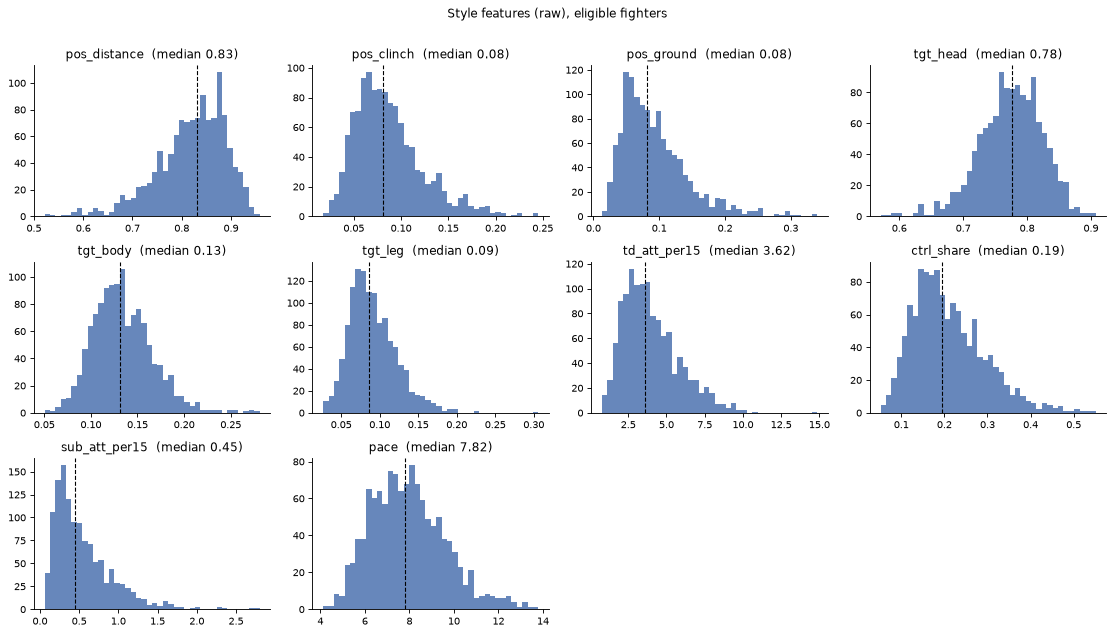

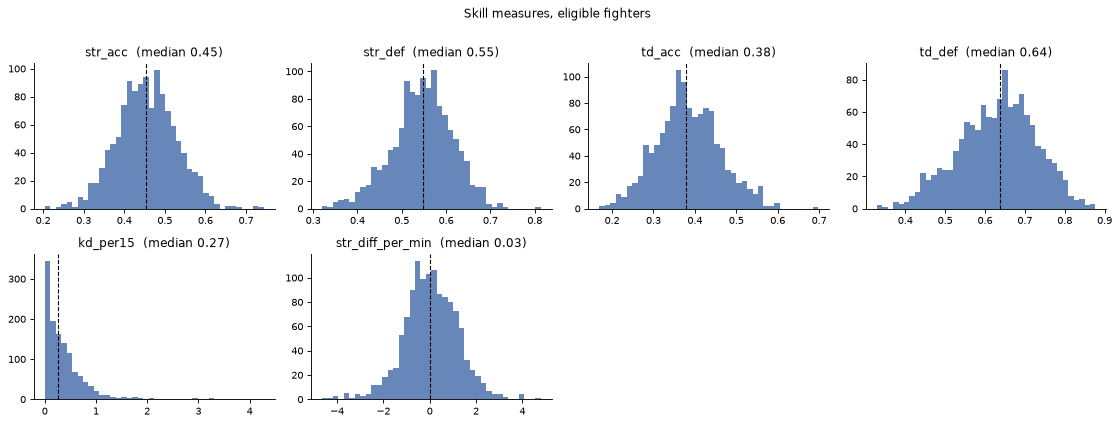

,count,mean,std,min,5%,25%,50%,75%,95%,max
pos_distance,1240.0,0.820,0.070,0.522,0.688,0.782,0.831,0.873,0.915,0.958
pos_clinch,1240.0,0.087,0.036,0.018,0.041,0.061,0.081,0.105,0.160,0.245
pos_ground,1240.0,0.093,0.050,0.013,0.034,0.056,0.082,0.118,0.193,0.340
tgt_head,1240.0,0.775,0.049,0.571,0.693,0.744,0.777,0.810,0.848,0.907
tgt_body,1240.0,0.134,0.032,0.050,0.088,0.112,0.131,0.153,0.189,0.281
tgt_leg,1240.0,0.091,0.031,0.027,0.049,0.069,0.087,0.109,0.148,0.306
td_att_per15,1240.0,3.986,1.824,0.777,1.644,2.633,3.624,5.019,7.575,14.843
ctrl_share,1240.0,0.210,0.083,0.052,0.099,0.149,0.194,0.263,0.366,0.551
sub_att_per15,1240.0,0.543,0.369,0.059,0.152,0.277,0.450,0.710,1.234,2.801
pace,1240.0,7.942,1.654,4.128,5.529,6.719,7.825,8.983,10.838,13.790


In [3]:
def hist_grid(df, cols, title, bins=40):
    fig, axes = plt.subplots(int(np.ceil(len(cols) / 4)), 4, figsize=(14, 2.6 * int(np.ceil(len(cols) / 4))))
    for ax, c in zip(axes.flat, cols):
        x = df[c].dropna()
        ax.hist(x, bins=bins, color="#4C72B0", alpha=0.85)
        ax.axvline(x.median(), color="k", lw=1, ls="--")
        ax.set_title(f"{c}  (median {x.median():.2f})")
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.01, fontsize=11)
    fig.tight_layout()
    plt.show()

hist_grid(elig, STYLE, "Style features (raw), eligible fighters")
hist_grid(elig, SKILL, "Skill measures, eligible fighters")
display(elig[STYLE + SKILL].describe(percentiles=[.05, .25, .5, .75, .95]).T)

### By weight class

Raw (unstandardized) values. The within-division z-scores remove these differences by construction.

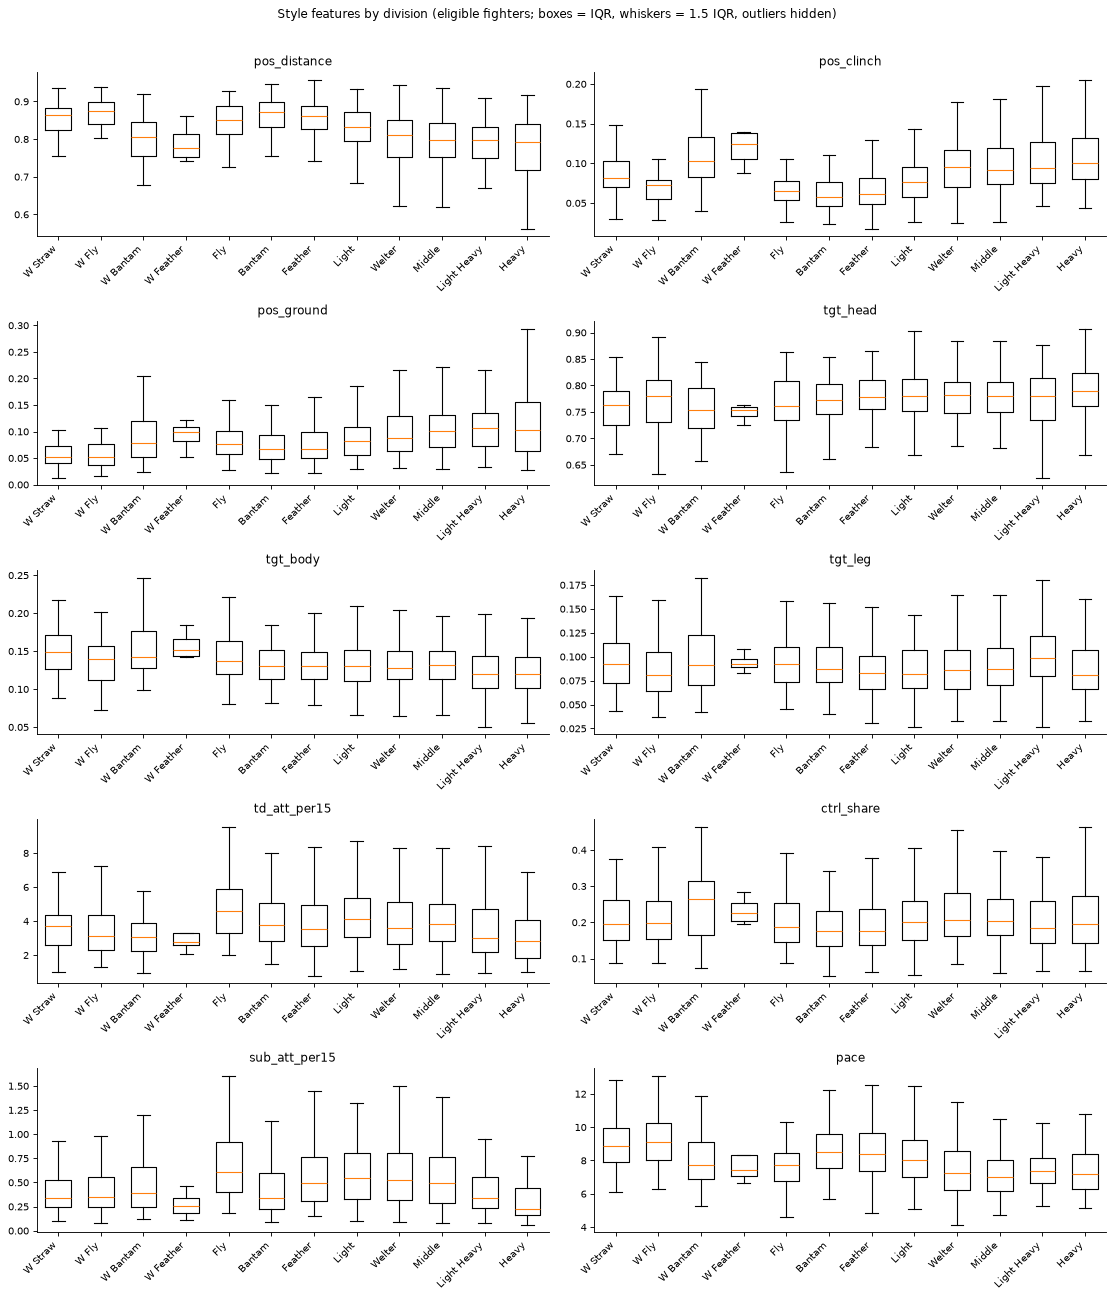

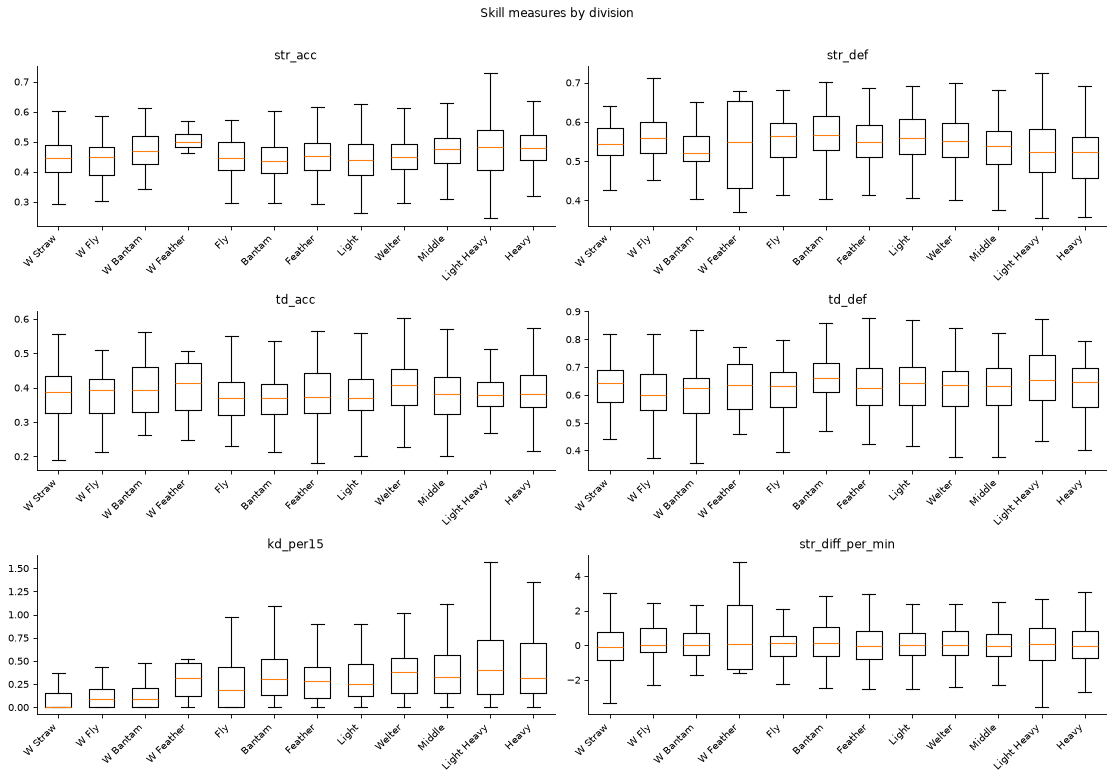

,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min
division,,,,,,,,,,,,,,,,,
Women's Strawweight,63,0.864,0.082,0.053,0.763,0.149,0.092,3.738,0.196,0.341,8.887,0.445,0.544,0.387,0.642,0.000,-0.092
Women's Flyweight,46,0.875,0.073,0.053,0.781,0.139,0.081,3.115,0.198,0.345,9.097,0.449,0.560,0.393,0.600,0.091,0.023
Women's Bantamweight,41,0.806,0.103,0.079,0.754,0.142,0.091,3.073,0.263,0.389,7.733,0.468,0.521,0.392,0.624,0.092,0.040
Women's Featherweight,4,0.776,0.125,0.098,0.753,0.152,0.093,2.744,0.225,0.256,7.435,0.499,0.548,0.412,0.636,0.315,0.092
Flyweight,74,0.849,0.065,0.076,0.761,0.137,0.092,4.574,0.186,0.603,7.731,0.447,0.564,0.370,0.630,0.184,0.116
Bantamweight,120,0.872,0.058,0.068,0.773,0.131,0.088,3.788,0.177,0.342,8.503,0.435,0.566,0.369,0.660,0.306,0.149
Featherweight,128,0.860,0.062,0.068,0.778,0.131,0.082,3.550,0.177,0.497,8.372,0.451,0.550,0.371,0.623,0.278,-0.068
Lightweight,206,0.831,0.076,0.083,0.781,0.131,0.082,4.139,0.201,0.543,7.999,0.438,0.560,0.369,0.642,0.254,0.021
Welterweight,186,0.810,0.095,0.088,0.782,0.128,0.086,3.614,0.206,0.522,7.251,0.451,0.552,0.409,0.635,0.380,0.023


In [4]:
divs = [d for d in DIV_ORDER if d in set(elig["division"])]
def box_by_div(cols, title):
    fig, axes = plt.subplots(int(np.ceil(len(cols) / 2)), 2, figsize=(14, 3.2 * int(np.ceil(len(cols) / 2))))
    for ax, c in zip(axes.flat, cols):
        data = [elig.loc[elig["division"] == d, c].dropna() for d in divs]
        ax.boxplot(data, showfliers=False, widths=0.6)
        ax.set_xticks(range(1, len(divs) + 1), [d.replace("Women's ", "W ").replace("weight", "") for d in divs], rotation=45, ha="right")
        ax.set_title(c)
    for ax in list(axes.flat)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.01, fontsize=11)
    fig.tight_layout()
    plt.show()

box_by_div(STYLE, "Style features by division (eligible fighters; boxes = IQR, whiskers = 1.5 IQR, outliers hidden)")
box_by_div(SKILL, "Skill measures by division")
med = elig.groupby("division")[STYLE + SKILL].median().reindex(divs)
med.insert(0, "fighters", elig["division"].value_counts().reindex(divs))
display(med)

## 3. Correlations

Computed on eligible fighters. Style features use their within-division z-scores (the clustering inputs). Skill measures are also
z-scored within the same groups here, so division differences don't create spurious correlations. Pearson correlation.

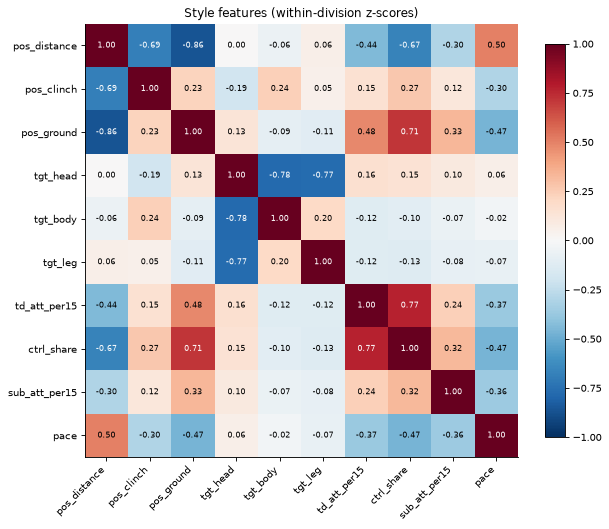

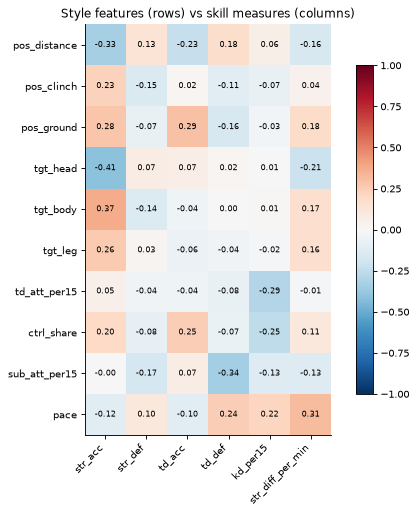

In [5]:
zs = elig[[f"z_{c}" for c in STYLE]].set_axis(STYLE, axis=1)
grp = elig["std_group"]
zk = elig[SKILL].groupby(grp).transform(lambda s: (s - s.mean()) / s.std(ddof=0))

def heat(m, title, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else "black")
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

style_corr = zs.corr()
heat(style_corr, "Style features (within-division z-scores)", (8, 7))
cross = pd.concat([zs, zk], axis=1).corr().loc[STYLE, SKILL]
heat(cross, "Style features (rows) vs skill measures (columns)", (6.5, 6.5))

In [6]:
pairs = style_corr.where(np.triu(np.ones(style_corr.shape, bool), 1)).stack().rename("r").reset_index()
pairs = pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index)
print("Strongest style-style correlations (mix shares are compositional, so some negatives are built in):")
display(pairs.head(10).reset_index(drop=True))
cp = cross.stack().rename("r").reset_index().rename(columns={"level_0": "style", "level_1": "skill"})
print("Strongest style-skill correlations:")
display(cp.reindex(cp["r"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True))

Strongest style-style correlations (mix shares are compositional, so some negatives are built in):


,level_0,level_1,r
0,pos_distance,pos_ground,-0.862
1,tgt_head,tgt_body,-0.779
2,tgt_head,tgt_leg,-0.769
3,td_att_per15,ctrl_share,0.768
4,pos_ground,ctrl_share,0.714
5,pos_distance,pos_clinch,-0.685
6,pos_distance,ctrl_share,-0.670
7,pos_distance,pace,0.502
8,pos_ground,td_att_per15,0.484
9,ctrl_share,pace,-0.468


Strongest style-skill correlations:


,style,skill,r
0,tgt_head,str_acc,-0.410
1,tgt_body,str_acc,0.370
2,sub_att_per15,td_def,-0.342
3,pos_distance,str_acc,-0.330
4,pace,str_diff_per_min,0.314
5,pos_ground,td_acc,0.293
6,td_att_per15,kd_per15,-0.290
7,pos_ground,str_acc,0.281
8,tgt_leg,str_acc,0.264
9,ctrl_share,kd_per15,-0.252


## 4. Highest and lowest 10 fighters on each feature

Eligible fighters. Style features and takedown accuracy/defense are **shrunk** (prior = `features.PRIOR_MINUTES` minutes of division-average fighting; see section 5). Other skill measures are raw.

In [7]:
def extremes(col):
    d = elig.dropna(subset=[col])
    cols = ["fighter_name", "division", "n_fights", col]
    top = d.nlargest(10, col)[cols].reset_index(drop=True)
    bot = d.nsmallest(10, col)[cols].reset_index(drop=True)
    t = pd.concat({"highest": top, "lowest": bot}, axis=1)
    t.index = range(1, 11)
    return t

for col in STYLE + SKILL:
    print(f"\n=== {col} ===")
    display(extremes(col))


=== pos_distance ===


highest                                                    lowest                                         
            fighter_name           division n_fights pos_distance     fighter_name           division n_fights pos_distance
1               Nam Phan      Featherweight        8        0.958    Randy Couture  Light Heavyweight       20        0.522
2            Andre Ewell       Bantamweight        9        0.947    Matt Lindland       Middleweight       12        0.530
3   Santiago Ponzinibbio       Welterweight       21        0.944        Jon Fitch       Welterweight       18        0.541
4          Sean O'Malley       Bantamweight       16        0.942   Cain Velasquez        Heavyweight       15        0.562
5         Viviane Araujo  Women's Flyweight       13        0.940  Jailton Almeida        Heavyweight       11        0.566
6           Alatengheili       Bantamweight        9        0.939       Mark Munoz       Middleweight       15        0.581
7          Calvin Kattar      Featherweight       15        0.939     Jorge Rivera       Middleweight       15        0.581
8       Daniel Rodriguez       Welterweight       15        0.937    Renato Sobral  Light Heavyweight       10        0.585
9        Sean Strickland       Middleweight       25        0.937     Josh Barnett        Heavyweight       10        0.588
10       Chris Gutierrez       Bantamweight       15        0.936      Matt Hughes       Welterweight       24        0.589


=== pos_clinch ===


highest                                                          lowest                                   
        fighter_name              division n_fights pos_clinch          fighter_name       division n_fights pos_clinch
1       Josh Barnett           Heavyweight       10      0.245              Nam Phan  Featherweight        8      0.018
2       Jorge Rivera          Middleweight       15      0.244         Calvin Kattar  Featherweight       15      0.020
3      Aaron Simpson          Middleweight       11      0.225         Sean O'Malley   Bantamweight       16      0.024
4        Yana Santos  Women's Bantamweight       12      0.223         Giga Chikadze  Featherweight       12      0.024
5      Lina Lansberg  Women's Bantamweight       11      0.219          Alatengheili   Bantamweight        9      0.025
6    Timothy Johnson           Heavyweight        7      0.209      Daniel Rodriguez   Welterweight       15      0.025
7       Cheick Kongo           Heavyweight       18      0.206  Santiago Ponzinibbio   Welterweight       21      0.025
8      Kendall Grove          Middleweight       13      0.202         Tony Ferguson    Lightweight       24      0.026
9        Phil Baroni          Middleweight       10      0.201       Sean Strickland   Middleweight       25      0.026
10  Anthony Hamilton           Heavyweight       10      0.200       Kai Kara-France      Flyweight       13      0.026


=== pos_ground ===


highest                                                        lowest                                          
           fighter_name           division n_fights pos_ground           fighter_name              division n_fights pos_ground
1       Jailton Almeida        Heavyweight       11      0.340     Joanna Jedrzejczyk   Women's Strawweight       15      0.013
2           Matt Hughes       Welterweight       24      0.336          Jennifer Maia     Women's Flyweight       12      0.016
3         Renato Sobral  Light Heavyweight       10      0.315            Ji Yeon Kim     Women's Flyweight       10      0.016
4          Brock Lesnar        Heavyweight        8      0.303            Jessica Eye     Women's Flyweight       16      0.021
5          Chael Sonnen       Middleweight       14      0.298           Emily Ducote   Women's Strawweight        5      0.021
6             Jon Fitch       Welterweight       18      0.296  Karolina Kowalkiewicz   Women's Strawweight       19      0.021
7      Alexandr Romanov        Heavyweight       10      0.294            Andre Ewell          Bantamweight        9      0.022
8   Khabib Nurmagomedov        Lightweight       13      0.291          Hakeem Dawodu         Featherweight       10      0.022
9         Randy Couture  Light Heavyweight       20      0.284         Alice Ardelean   Women's Strawweight        5      0.023
10      Ricco Rodriguez        Heavyweight        7      0.282          Bethe Correia  Women's Bantamweight       12      0.023

... (22 outputs left out)


=== kd_per15 ===


highest                                          lowest                                       
      fighter_name      division n_fights kd_per15    fighter_name             division n_fights kd_per15
1   Drew McFedries  Middleweight        9    4.272      Davi Ramos          Lightweight        7      0.0
2    Chris Daukaus   Heavyweight        8    3.536      Sean Sherk          Lightweight       12      0.0
3     Tom Aspinall   Heavyweight       10    3.270     Artem Lobov        Featherweight        7      0.0
4    Ateba Gautier  Middleweight        5    3.267    Emily Ducote  Women's Strawweight        5      0.0
5       Uros Medic  Welterweight       11    3.203    Jorge Gurgel          Lightweight        7      0.0
6    Manuel Torres   Lightweight        7    2.927     Rob Kimmons         Middleweight        7      0.0
7      Todd Duffee   Heavyweight        6    2.915  Marvin Eastman    Light Heavyweight        5      0.0
8    Carlos Prates  Welterweight        8    2.325   Kailin Curran  Women's Strawweight        7      0.0
9   Mauricio Ruffy   Lightweight        6    2.058   Chris Padilla          Lightweight        5      0.0
10  Gilbert Urbina  Welterweight        5    2.044      CJ Vergara            Flyweight        8      0.0


=== str_diff_per_min ===


highest                                                                   lowest                                               
          fighter_name               division n_fights str_diff_per_min            fighter_name             division n_fights str_diff_per_min
1    Cristiane Justino  Women's Featherweight        7            4.798            Ken Shamrock    Light Heavyweight        5           -4.646
2       Cain Velasquez            Heavyweight       15            4.080          Daniel Lacerda            Flyweight        6           -4.333
3            Wang Cong      Women's Flyweight        6            4.023          Louis Gaudinot            Flyweight        5           -4.088
4         Tom Aspinall            Heavyweight       10            4.012             Jimmy Flick            Flyweight        6           -4.025
5      Navajo Stirling      Light Heavyweight        6            3.945  Montserrat Conejo Ruiz  Women's Strawweight        5           -3.981
6          Todd Duffee            Heavyweight        6            3.255             David Heath    Light Heavyweight        5           -3.682
7    Terrance McKinney            Lightweight       14            3.193           Kyle Prepolec          Lightweight        5           -3.587
8           Ciryl Gane            Heavyweight       14            3.095            Tresean Gore         Middleweight        7           -3.586
9      Michael Morales           Welterweight        7            3.035          Ike Villanueva    Light Heavyweight        6           -3.581
10  Joanna Jedrzejczyk    Women's Strawweight       15            3.034           Elvis Sinosic    Light Heavyweight        7           -3.473

## 5. Shrinkage toward the division average

Every ratio feature is computed as (fighter's numerator + P × division numerator per second) / (fighter's denominator + P × division
denominator per second), where P is the prior in seconds. That is, each fighter gets P seconds of **division-average fighting** added
to their totals. Division averages are pooled over eligible fighters in the fighter's standardization group, from pre-`as_of` fights only.

### Choosing P: held-out check

For fighters with 10+ fights, features are built from an early sample of their fights with prior P and compared with the **raw**
values from their later fights. The error is fight-time-weighted MSE divided by the variance of the later values, so 1.0 means
"no better than guessing the population mean." Two splits: first half → second half, and first 5 fights → fights 6+.
The division averages here use all fights. That is fine for choosing one number, but it isn't a leakage-free evaluation.

first half -> second half: 618 fighters. Best mean error at P = 120 min; within 5% of best from P = 60 min


,mean,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace,td_acc,td_def
prior_min,,,,,,,,,,,,,
0,1.36,1.64,1.26,2.16,0.70,0.76,0.81,0.61,0.93,3.15,0.82,2.09,1.37
10,1.09,1.28,1.05,1.62,0.62,0.67,0.72,0.55,0.80,2.47,0.70,1.52,1.10
15,1.02,1.17,0.98,1.46,0.60,0.64,0.70,0.53,0.77,2.25,0.67,1.43,1.04
20,0.97,1.10,0.93,1.35,0.59,0.62,0.68,0.52,0.74,2.07,0.65,1.37,1.00
30,0.90,0.99,0.87,1.19,0.58,0.61,0.67,0.51,0.70,1.80,0.62,1.28,0.95
45,0.84,0.90,0.81,1.05,0.59,0.60,0.66,0.51,0.68,1.55,0.60,1.20,0.91
60,0.81,0.85,0.78,0.98,0.60,0.61,0.66,0.52,0.67,1.38,0.60,1.15,0.89
90,0.78,0.80,0.76,0.90,0.62,0.63,0.68,0.55,0.68,1.20,0.62,1.09,0.87
120,0.78,0.79,0.76,0.87,0.65,0.66,0.70,0.59,0.69,1.11,0.64,1.06,0.87


best P per feature: {'pos_distance': 120, 'pos_clinch': 120, 'pos_ground': 180, 'tgt_head': 30, 'tgt_body': 45, 'tgt_leg': 45, 'td_att_per15': 30, 'ctrl_share': 60, 'sub_att_per15': 240, 'pace': 60, 'td_acc': 240, 'td_def': 120}
first 5 -> fights 6+: 618 fighters. Best mean error at P = 120 min; within 5% of best from P = 60 min


,mean,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace,td_acc,td_def
prior_min,,,,,,,,,,,,,
0,2.36,3.25,2.16,4.50,0.88,1.03,1.12,0.73,1.56,7.10,1.03,3.06,1.95
10,1.46,1.91,1.41,2.56,0.69,0.77,0.87,0.59,1.17,3.65,0.82,1.81,1.25
15,1.27,1.61,1.23,2.12,0.66,0.72,0.81,0.56,1.06,2.98,0.77,1.64,1.15
20,1.15,1.40,1.11,1.81,0.64,0.69,0.78,0.54,0.98,2.52,0.74,1.52,1.09
30,1.00,1.14,0.96,1.44,0.62,0.65,0.74,0.52,0.88,1.96,0.70,1.37,1.01
45,0.89,0.95,0.85,1.16,0.62,0.64,0.72,0.53,0.80,1.52,0.68,1.25,0.95
60,0.84,0.86,0.80,1.01,0.64,0.65,0.72,0.55,0.76,1.29,0.68,1.17,0.92
90,0.80,0.79,0.76,0.89,0.68,0.67,0.74,0.59,0.75,1.07,0.70,1.10,0.89
120,0.80,0.77,0.76,0.85,0.71,0.70,0.76,0.63,0.76,0.98,0.72,1.06,0.89


best P per feature: {'pos_distance': 120, 'pos_clinch': 120, 'pos_ground': 180, 'tgt_head': 30, 'tgt_body': 45, 'tgt_leg': 45, 'td_att_per15': 30, 'ctrl_share': 90, 'sub_att_per15': 240, 'pace': 60, 'td_acc': 240, 'td_def': 120}


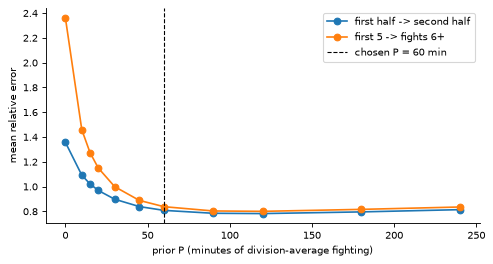

eligible fighters' own fight time: p10 51, p25 68, median 100 min
weight on own data at P = 60: p10 fighter 46%, median fighter 62%


In [8]:
priors_all = F.division_priors(F.aggregate(ff), profiles.set_index("fighter_id")["std_group"], profiles.set_index("fighter_id")["eligible"])
cnt = ff.groupby("fighter_id").size()
ids = cnt[cnt >= 10].index.intersection(profiles.loc[profiles["std_group"].notna(), "fighter_id"])
fx = ff[ff["fighter_id"].isin(ids)].sort_values(["fighter_id", "event_date"]).copy()
fx["k"] = fx.groupby("fighter_id").cumcount()
fx["n"] = fx.groupby("fighter_id")["fight_id"].transform("size")
FEATS = STYLE + F.SHRUNK_SKILL
KS = [0, 10, 15, 20, 30, 45, 60, 90, 120, 180, 240]

def heldout(first, second):
    a1, a2 = F.aggregate(first), F.aggregate(second)
    target, w = F.ratio_features(a2, None, 0), a2["time_s"]
    rows = []
    for k in KS:
        pred = F.ratio_features(a1, priors_all.loc[a1.index], k)
        r = {"prior_min": k}
        for f in FEATS:
            ok = pred[f].notna() & target[f].notna()
            y, yh, ww = target.loc[ok, f], pred.loc[ok, f], w[ok]
            r[f] = np.average((y - yh) ** 2, weights=ww) / np.average((y - np.average(y, weights=ww)) ** 2, weights=ww)
        rows.append(r)
    res = pd.DataFrame(rows).set_index("prior_min")
    res.insert(0, "mean", res[FEATS].mean(axis=1))
    return res

splits = {"first half -> second half": heldout(fx[fx.k < fx.n // 2], fx[fx.k >= fx.n // 2]),
          "first 5 -> fights 6+": heldout(fx[fx.k < 5], fx[fx.k >= 5])}
for name, res in splits.items():
    print(f"{name}: {len(ids)} fighters. Best mean error at P = {res['mean'].idxmin()} min; "
          f"within 5% of best from P = {res.index[res['mean'] <= 1.05 * res['mean'].min()].min()} min")
    display(res.round(2))
    print("best P per feature:", res[FEATS].idxmin().to_dict())

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, res in splits.items():
    ax.plot(res.index, res["mean"], marker="o", label=name)
ax.axvline(F.PRIOR_MINUTES, color="k", ls="--", lw=1, label=f"chosen P = {F.PRIOR_MINUTES:g} min")
ax.set_xlabel("prior P (minutes of division-average fighting)")
ax.set_ylabel("mean relative error")
ax.legend()
plt.show()
e = profiles[profiles["eligible"]]
print("eligible fighters' own fight time: p10 %.0f, p25 %.0f, median %.0f min" % tuple(e["fight_time_min"].quantile([.1, .25, .5])))
print(f"weight on own data at P = {F.PRIOR_MINUTES:g}: p10 fighter %.0f%%, median fighter %.0f%%" % tuple(
    100 * t / (t + F.PRIOR_MINUTES) for t in e["fight_time_min"].quantile([.1, .5])))

### How the top-10 lists change with P

Top 10 eligible fighters at P = 0 (raw), 30, 60 (chosen) and 120 minutes, for the features most affected by small samples.
Minutes of fight time are in parentheses.

In [9]:
variants = {k: F.build_profiles(None, ff, prior_minutes=k) for k in (0, 30, 60, 120)}
def top10(col, k, largest=True):
    d = variants[k]
    d = d[d["eligible"]].dropna(subset=[col])
    d = d.nlargest(10, col) if largest else d.nsmallest(10, col)
    return [f"{r.fighter_name} {getattr(r, col):.2f} ({r.fight_time_min:.0f})" for r in d.itertuples()]

for col in ["sub_att_per15", "td_att_per15", "pos_clinch", "ctrl_share", "pace", "td_acc", "td_def"]:
    t = pd.DataFrame({f"P = {k}": top10(col, k) for k in variants}, index=range(1, 11))
    base = set(n.rsplit(" ", 2)[0] for n in t["P = 0"])
    kept = sum(n.rsplit(" ", 2)[0] in base for n in t["P = 60"])
    print(f"\n=== {col}: highest 10 === ({kept}/10 of the raw top 10 remain at P = 60)")
    display(t)


=== sub_att_per15: highest 10 === (6/10 of the raw top 10 remain at P = 60)


,P = 0,P = 30,P = 60,P = 120
1,Paul Sass 7.38 (28),Paul Sass 3.92 (28),Paul Sass 2.80 (28),Charles Oliveira 2.03 (295)
2,John Albert 6.14 (22),TJ Waldburger 3.38 (59),TJ Waldburger 2.68 (59),TJ Waldburger 1.98 (59)
3,TJ Waldburger 4.79 (59),Jaqueline Amorim 2.99 (60),Jaqueline Amorim 2.35 (60),Paul Sass 1.92 (28)
4,Jaqueline Amorim 4.27 (60),Dustin Hazelett 2.87 (54),Dustin Hazelett 2.27 (54),Jaqueline Amorim 1.71 (60)
5,Dustin Hazelett 4.14 (54),John Albert 2.85 (22),Charles Oliveira 2.26 (295),Dustin Hazelett 1.69 (54)
6,Valter Walker 3.59 (25),Renato Sobral 2.42 (81),Rousimar Palhares 2.00 (76),Chris Lytle 1.59 (216)
7,Shannon Gugerty 3.41 (35),Charles Oliveira 2.41 (295),Renato Sobral 2.00 (81),Hermes Franca 1.56 (150)
8,Tim Credeur 3.29 (36),Rousimar Palhares 2.41 (76),John Albert 1.97 (22),Rousimar Palhares 1.55 (76)
9,Jason High 3.26 (41),Jason High 2.13 (41),Hermes Franca 1.83 (150),Joe Lauzon 1.53 (213)
10,Renato Sobral 3.16 (81),Shannon Gugerty 2.13 (35),Chris Lytle 1.81 (216),Joe Stevenson 1.53 (165)



=== td_att_per15: highest 10 === (5/10 of the raw top 10 remain at P = 60)


,P = 0,P = 30,P = 60,P = 120
1,Quillan Salkilld 17.22 (29),Merab Dvalishvili 15.80 (299),Merab Dvalishvili 14.84 (299),Merab Dvalishvili 13.34 (299)
2,Merab Dvalishvili 16.95 (299),Mateusz Gamrot 11.86 (159),Mateusz Gamrot 10.83 (159),Mateusz Gamrot 9.45 (159)
3,Myktybek Orolbai 14.87 (62),Tony Gravely 11.43 (88),Tony Gravely 9.99 (88),Wilson Reis 8.79 (148)
4,Jason Witt 14.26 (33),Myktybek Orolbai 11.32 (62),Wilson Reis 9.94 (148),Demian Maia 8.68 (410)
5,Gregor Gillespie 14.23 (59),Rodolfo Vieira 11.08 (115),Rodolfo Vieira 9.86 (115),Nik Lentz 8.47 (314)
6,Tony Gravely 13.85 (88),Gregor Gillespie 10.91 (59),Anthony Hernandez 9.74 (137),Anthony Hernandez 8.40 (137)
7,Gadzhimurad Antigulov 13.78 (21),Wilson Reis 10.81 (148),Muhammad Mokaev 9.55 (88),Rodolfo Vieira 8.36 (115)
8,Mateusz Gamrot 13.26 (159),Anthony Hernandez 10.77 (137),Myktybek Orolbai 9.53 (62),Tony Gravely 8.36 (88)
9,Jonathan Brookins 13.11 (43),Muhammad Mokaev 10.75 (88),Zach Makovsky 9.47 (105),Khabib Nurmagomedov 8.32 (172)
10,Rodolfo Vieira 12.93 (115),Quillan Salkilld 10.66 (29),Jacob Malkoun 9.36 (100),Michel Prazeres 8.24 (171)



=== pos_clinch: highest 10 === (2/10 of the raw top 10 remain at P = 60)


,P = 0,P = 30,P = 60,P = 120
1,Ken Shamrock 0.44 (23),Josh Barnett 0.28 (92),Josh Barnett 0.25 (92),Josh Barnett 0.20 (92)
2,Rob Kimmons 0.38 (51),Jorge Rivera 0.28 (116),Jorge Rivera 0.24 (116),Jorge Rivera 0.20 (116)
3,Josh Samman 0.38 (41),Aaron Simpson 0.25 (127),Aaron Simpson 0.23 (127),Yana Santos 0.20 (154)
4,Terry Martin 0.36 (44),Lina Lansberg 0.25 (145),Yana Santos 0.22 (154),Aaron Simpson 0.19 (127)
5,Josh Barnett 0.34 (92),Yana Santos 0.24 (154),Lina Lansberg 0.22 (145),Lina Lansberg 0.19 (145)
6,Bartosz Fabinski 0.34 (51),Timothy Johnson 0.24 (83),Timothy Johnson 0.21 (83),Cheick Kongo 0.18 (163)
7,Jorge Rivera 0.33 (116),Anthony Hamilton 0.24 (63),Cheick Kongo 0.21 (163),Timothy Johnson 0.18 (83)
8,Marvin Eastman 0.33 (32),Terry Martin 0.24 (44),Kendall Grove 0.20 (123),Randy Couture 0.17 (248)
9,Antoni Hardonk 0.33 (51),Phil Baroni 0.23 (97),Phil Baroni 0.20 (97),Brandon Vera 0.17 (164)
10,Paul Buentello 0.32 (42),Kendall Grove 0.23 (123),Anthony Hamilton 0.20 (63),Demetrious Johnson 0.17 (334)


... (4 outputs left out)


=== td_acc: highest 10 === (0/10 of the raw top 10 remain at P = 60)


,P = 0,P = 30,P = 60,P = 120
1,Houston Alexander 1.00 (25),Georges St-Pierre 0.72 (343),Georges St-Pierre 0.70 (343),Georges St-Pierre 0.67 (343)
2,James Head 1.00 (37),Forrest Petz 0.68 (81),Taila Santos 0.60 (105),Valentina Shevchenko 0.57 (362)
3,Drew McFedries 1.00 (21),Nordine Taleb 0.66 (124),Nordine Taleb 0.60 (124),Bartosz Fabinski 0.55 (51)
4,Hyun Gyu Lim 1.00 (64),Taila Santos 0.66 (105),Bartosz Fabinski 0.60 (51),Karo Parisyan 0.54 (151)
5,Hannah Cifers 1.00 (58),Pat Miletich 0.65 (37),Robbie Lawler 0.60 (318),Taila Santos 0.54 (105)
6,Tim Sylvia 1.00 (138),Darrick Minner 0.65 (47),Valentina Shevchenko 0.59 (362),Nordine Taleb 0.54 (124)
7,Ateba Gautier 1.00 (28),Robbie Lawler 0.65 (318),Forrest Petz 0.58 (81),Robbie Lawler 0.54 (318)
8,Andre Fialho 1.00 (61),Bartosz Fabinski 0.64 (51),Cheick Kongo 0.57 (163),Cheick Kongo 0.54 (163)
9,Jens Pulver 1.00 (107),Alessio Sakara 0.64 (76),Alessio Sakara 0.57 (76),Liz Carmouche 0.53 (144)
10,Lyman Good 1.00 (55),Ikram Aliskerov 0.62 (41),Karo Parisyan 0.57 (151),Serghei Spivac 0.53 (126)



=== td_def: highest 10 === (0/10 of the raw top 10 remain at P = 60)


,P = 0,P = 30,P = 60,P = 120
1,Viktor Pesta 1.00 (50),Jon Jones 0.90 (357),Jose Aldo 0.88 (380),Jose Aldo 0.85 (380)
2,Luiz Cane 1.00 (54),Jose Aldo 0.90 (380),Jon Jones 0.87 (357),Gleison Tibau 0.84 (309)
3,Ateba Gautier 1.00 (28),Gleison Tibau 0.89 (309),Gleison Tibau 0.87 (309),Petr Yan 0.83 (282)
4,Eddie Alvarez 1.00 (89),Eddie Wineland 0.89 (151),Shane Burgos 0.86 (140),Jon Jones 0.83 (357)
5,Bo Nickal 1.00 (51),Shane Burgos 0.89 (140),Eddie Wineland 0.86 (151),Shane Burgos 0.82 (140)
6,Abus Magomedov 1.00 (78),Julio Arce 0.88 (122),Renan Barao 0.85 (235),Eddie Wineland 0.82 (151)
7,Tom Aspinall 1.00 (23),Renan Barao 0.88 (235),Petr Yan 0.85 (282),Renan Barao 0.81 (235)
8,Yazmin Jauregui 1.00 (42),Belal Muhammad 0.87 (348),Belal Muhammad 0.84 (348),Donald Cerrone 0.81 (357)
9,Philipe Lins 1.00 (64),Rafael Fiziev 0.87 (150),Rafael Fiziev 0.84 (150),Belal Muhammad 0.80 (348)
10,Jason Witt 1.00 (33),Kamaru Usman 0.87 (364),Donald Cerrone 0.84 (357),Rafael Fiziev 0.80 (150)


## 6. Notes

- The position mix and target mix each sum to 1, so each mix has only 2 free dimensions. For clustering, `features.CLUSTER_FEATURES`
  drops `pos_distance` and `tgt_head`. They stay in the saved profiles for interpretation.
- Shares and rates are pooled over fights, then shrunk toward the division average (section 5), so fighters with little cage time are
  pulled toward typical values instead of producing extreme ones.